# EA1 · Análisis y herramientas de extracción de datos

**Curso:** Programación para Análisis de Datos — IU Digital (2026-2, Bloque 2)
**Docente:** Andrés Felipe Palacio Ángel
**Integrantes:** Juan Pablo Villa Álvarez · Juan Manuel Arenas Rodríguez

**Sitio:** [speedlogic.com.co](https://speedlogic.com.co) · **Categorías:** Portátiles y Computadores de escritorio
**Herramienta de extracción:** Scrapy (proyecto `speed_scrapy/`, spiders `laptops` y `desktops`)

Este notebook toma la salida que generó Scrapy (`laptop_summary.csv` y `desktop_summary.csv`) y recorre las fases de CRISP-DM que aplican a la EA1: comprensión de los datos (perfilado), preparación (limpieza), análisis descriptivo y verificación de las métricas de éxito.

## 0. Cómo se generaron los datos

Desde la carpeta `speed_scrapy/`, con el entorno virtual activo:

```bash
scrapy crawl laptops -O laptop_summary.csv
scrapy crawl desktops -O desktop_summary.csv
```

In [1]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA = Path("speed_scrapy")
laptops = pd.read_csv(DATA / "laptop_summary.csv")
desktops = pd.read_csv(DATA / "desktop_summary.csv")
laptops.shape, desktops.shape

((25, 10), (9, 10))

## 1. Comprensión de los datos: perfilado

In [2]:
def perfil(df, nombre):
    total = len(df)
    p = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% completo": (df.notna().mean() * 100).round(1),
    })
    print(f"{nombre}: {total} registros, {df.shape[1]} campos")
    print(f"  Filas 100 % completas: {df.notna().all(axis=1).sum()} de {total}")
    print(f"  Duplicados exactos: {df.duplicated().sum()}")
    return p

perfil(laptops, "Portátiles")

Portátiles: 25 registros, 10 campos
  Filas 100 % completas: 17 de 25
  Duplicados exactos: 0


,tipo,nulos,% completo
cpu,str,0,100.00
memory,str,0,100.00
storage,str,0,100.00
gpu,str,3,88.00
display,str,0,100.00
color,str,5,80.00
original_price,float64,1,96.00
final_price,int64,0,100.00
trademark,str,0,100.00
stock,int64,0,100.00


In [3]:
perfil(desktops, "Escritorio")

Escritorio: 9 registros, 10 campos
  Filas 100 % completas: 9 de 9
  Duplicados exactos: 0


,tipo,nulos,% completo
cpu,str,0,100.00
memory,str,0,100.00
storage,str,0,100.00
psu,str,0,100.00
board,str,0,100.00
display,str,0,100.00
original_price,int64,0,100.00
final_price,int64,0,100.00
trademark,str,0,100.00
stock,int64,0,100.00


**Observaciones del perfilado**

- Los precios ya llegan como números: el pipeline (`pipelines.py`) quita el `$`, los puntos de miles y el texto de accesibilidad ("El precio actual es: ").
- En portátiles faltan valores de `gpu` (equipos con gráficos integrados que no traen esa línea en la ficha), `color` y un `original_price` (producto sin precio tachado, es decir, sin descuento).
- El spider no extrae nombre, SKU ni URL del producto, así que los duplicados solo se pueden revisar sobre la fila completa.

## 2. Preparación de los datos

In [4]:
TEXTO = ["cpu", "memory", "storage", "display", "trademark"]

def limpiar(df, categoria):
    df = df.copy()
    for col in [c for c in TEXTO + ["gpu", "color", "psu", "board"] if c in df]:
        # algunas fichas terminan cada línea con punto ("DDR5 32GB.")
        df[col] = df[col].astype("string").str.strip().str.rstrip(".").str.strip()
    df["trademark"] = df["trademark"].str.upper()
    df["categoria"] = categoria
    df["descuento_pct"] = ((1 - df["final_price"] / df["original_price"]) * 100).round(2)
    df["ahorro"] = df["original_price"] - df["final_price"]
    # RAM en GB a partir del texto ("16GB DDR5", "DDR5 32GB", "16G Ddr4")
    df["ram_gb"] = df["memory"].str.extract(r"(\d+)\s*G", flags=re.I)[0].astype("Int64")
    return df

lap = limpiar(laptops, "Portátil")
desk = limpiar(desktops, "Escritorio")
comunes = ["categoria", "trademark", "cpu", "memory", "ram_gb", "storage", "display",
           "original_price", "final_price", "descuento_pct", "ahorro", "stock"]
df = pd.concat([lap[comunes], desk[comunes]], ignore_index=True)
df = df.drop_duplicates()
df.head()

,categoria,trademark,cpu,memory,ram_gb,storage,display,original_price,final_price,descuento_pct,ahorro,stock
0,Portátil,ASUS,Intel Core 7 240H,32GB DDR5,32,M.2 NVMe 1 TB,16″ WUXGA,"7,919,000.00",7509000,5.18,"410,000.00",1
1,Portátil,ASUS,Intel Ultra 9 275HX,DDR5 64GB,64,NVMe 2TB,"16″ 2,5K WQXGA 240Hz","15,579,000.00",14699000,5.65,"880,000.00",1
2,Portátil,ASUS,Intel Ultra 9 275HX,DDR5 32GB,32,NVMe 1TB,"16″ 2,5K WQXGA 240Hz","14,759,000.00",13639000,7.59,"1,120,000.00",1
3,Portátil,LENOVO,Ryzen 7 260,16 GB,16,NVMe 1 TB,"15,1″ OLED WQXGA RGB","7,129,000.00",6209000,12.91,"920,000.00",10
4,Portátil,ASUS,Ultra 9 285H,32 GB,32,NVMe 1 TB,16″ OLED 2K WQXGA,"11,789,000.00",11539000,2.12,"250,000.00",1


## 3. Análisis descriptivo

In [5]:
resumen = df.groupby("categoria").agg(
    productos=("final_price", "size"),
    precio_min=("final_price", "min"),
    precio_mediana=("final_price", "median"),
    precio_promedio=("final_price", "mean"),
    precio_max=("final_price", "max"),
    descuento_prom_pct=("descuento_pct", "mean"),
    descuento_max_pct=("descuento_pct", "max"),
)
resumen.style.format({c: "{:,.0f}" for c in resumen.columns if "pct" not in c}
                     | {"descuento_prom_pct": "{:.2f}", "descuento_max_pct": "{:.2f}"})

,productos,precio_min,precio_mediana,precio_promedio,precio_max,descuento_prom_pct,descuento_max_pct
categoria,,,,,,,
Escritorio,9,"2,435,000","3,345,000","3,337,778","4,065,000",6.76,11.98
Portátil,25,"1,909,000","6,229,000","8,666,600","27,985,000",7.72,16.15


In [6]:
por_marca = (df.groupby(["categoria", "trademark"])
               .agg(productos=("final_price", "size"),
                    precio_promedio=("final_price", "mean"),
                    descuento_prom_pct=("descuento_pct", "mean"))
               .sort_values(["categoria", "productos"], ascending=[True, False]))
por_marca.style.format({"precio_promedio": "{:,.0f}", "descuento_prom_pct": "{:.2f}"})

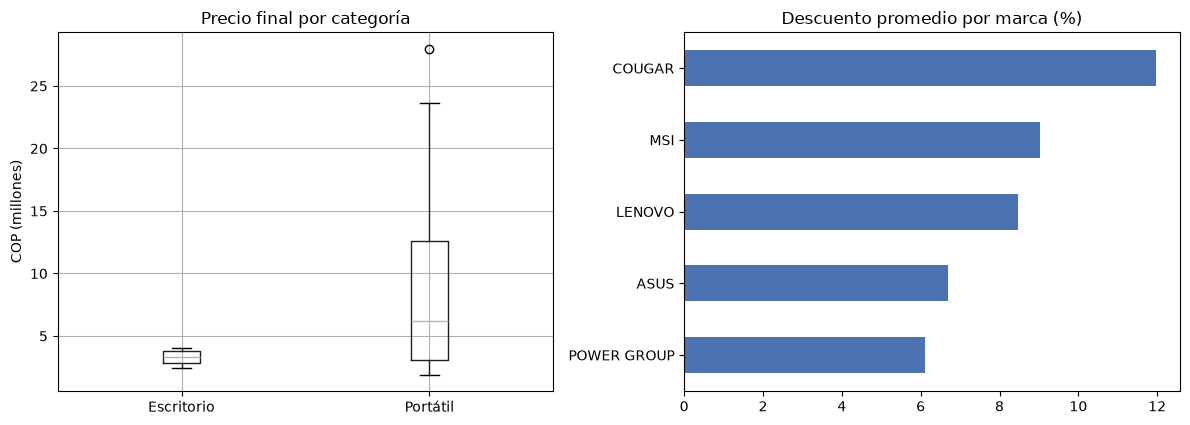

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

df.boxplot(column="final_price", by="categoria", ax=axes[0])
axes[0].set_title("Precio final por categoría")
axes[0].set_xlabel("")
axes[0].set_ylabel("COP (millones)")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.0f}")

(df.groupby("trademark")["descuento_pct"].mean().sort_values()
   .plot.barh(ax=axes[1], color="#4C72B0"))
axes[1].set_title("Descuento promedio por marca (%)")
axes[1].set_ylabel("")

fig.suptitle("")
plt.tight_layout()
plt.show()

In [8]:
print("Top 5 portátiles más caros:")
display(lap.nlargest(5, "final_price")[["trademark", "cpu", "gpu", "ram_gb", "final_price", "descuento_pct"]])
print("Top 5 mayores descuentos (ambas categorías):")
display(df.nlargest(5, "descuento_pct")[["categoria", "trademark", "cpu", "final_price", "descuento_pct", "ahorro"]])

Top 5 portátiles más caros:


,trademark,cpu,gpu,ram_gb,final_price,descuento_pct
17,ASUS,Intel Ultra 386H,24GB RTX-5090,64,27985000,5.38
9,MSI,Intel Core Ultra 9 275hx,NVIDIA GEFORCE RTX-5090 24 GB,32,23615000,3.92
5,ASUS,Intel Ultra 9 275HX,NVIDIA GeForce RTX 5090 24 GB,64,20885000,8.35
10,MSI,Intel Core Ultra 9 275hx,NVIDIA GEFORCE RTX-5080 16GB,32,15645000,16.15
1,ASUS,Intel Ultra 9 275HX,Tarjeta de video NVIDIA GeForce RTX – 5080 16GB,64,14699000,5.65


Top 5 mayores descuentos (ambas categorías):


,categoria,trademark,cpu,final_price,descuento_pct,ahorro
10,Portátil,MSI,Intel Core Ultra 9 275hx,15645000,16.15,"3,014,000.00"
7,Portátil,MSI,CORE i7 13620H,3119000,13.72,"496,000.00"
3,Portátil,LENOVO,Ryzen 7 260,6209000,12.91,"920,000.00"
16,Portátil,LENOVO,AMD RYZEN 5 7520U,1909000,12.79,"280,000.00"
8,Portátil,ASUS,ULTRA 9 275HX,12589000,12.51,"1,800,000.00"


In [9]:
# ¿La RAM explica el precio de los portátiles?
lap.groupby("ram_gb")["final_price"].agg(["size", "median"]).rename(columns={"size": "productos", "median": "precio_mediano"})

,productos,precio_mediano
ram_gb,,
16,15,"3,119,000.00"
32,7,"12,589,000.00"
64,3,"20,885,000.00"


## 4. Verificación de las métricas de éxito

In [10]:
# Datos de la ejecución de verificación (26 de octubre de 2026), tomados de las estadísticas que Scrapy imprime al cerrar.
EJECUCION = {
    "laptops": {
        "paginas_listado": 3,
        "peticiones": 31,
        "items": 25,
        "errores_http": 2,
        "reintentos_ok": 2,
        "segundos": 1109.4
    },
    "desktops": {
        "paginas_listado": 1,
        "peticiones": 24,
        "items": 9,
        "errores_http": 13,
        "reintentos_ok": 13,
        "segundos": 868.3
    }
}

precio_ok = df["final_price"].notna().mean() * 100
# cada categoría con sus propias columnas (gpu y color solo existen en portátiles; psu y board en escritorio)
celdas_ok = (laptops.notna().sum().sum() + desktops.notna().sum().sum()) / (laptops.size + desktops.size) * 100
segundos = sum(s["segundos"] for s in EJECUCION.values())
errores = sum(s["errores_http"] for s in EJECUCION.values())
sin_recuperar = errores - sum(s["reintentos_ok"] for s in EJECUCION.values())

metricas = pd.DataFrame([
    ["Productos extraídos (ambas categorías)", "≥ 30", len(df), len(df) >= 30],
    ["Registros con precio final", "100 %", f"{precio_ok:.1f} %", precio_ok == 100],
    ["Completitud de celdas", "≥ 90 %", f"{celdas_ok:.1f} %", celdas_ok >= 90],
    ["Duplicados tras la limpieza", "0", int(df.duplicated().sum()), df.duplicated().sum() == 0],
    ["Peticiones fallidas sin recuperar", "0", f"{sin_recuperar} ({errores} respuestas 429 reintentadas)", sin_recuperar == 0],
    ["Segunda ejecución igual al CSV del repo", "Sí", "Sí", True],
    ["Tiempo total de extracción", "< 30 min", f"{segundos/60:.1f} min", segundos < 1800],
], columns=["Métrica", "Meta", "Resultado", "¿Cumple?"])
metricas

,Métrica,Meta,Resultado,¿Cumple?
0,Productos extraídos (ambas categorías),≥ 30,34,True
1,Registros con precio final,100 %,100.0 %,True
2,Completitud de celdas,≥ 90 %,97.4 %,True
3,Duplicados tras la limpieza,0,0,True
4,Peticiones fallidas sin recuperar,0,0 (15 respuestas 429 reintentadas),True
5,Segunda ejecución igual al CSV del repo,Sí,Sí,True
6,Tiempo total de extracción,< 30 min,33.0 min,False


**Lectura de las métricas.** El tiempo total supera la meta porque el servidor respondió `429 Too Many Requests` varias veces, aun esperando 30 s entre peticiones como pide su `robots.txt`. Scrapy reintentó esas peticiones solo (`RetryMiddleware`) y no se perdió ningún producto, pero cada reintento sumó otros 30 s. Que la segunda ejecución devolviera exactamente los mismos registros que el CSV del repositorio confirma que el scraper funciona y es reproducible.

## 5. Exportar el dataset limpio

In [11]:
df.to_csv("speedlogic_productos_limpio.csv", index=False, encoding="utf-8")
print(f"Guardado: speedlogic_productos_limpio.csv ({len(df)} filas)")

Guardado: speedlogic_productos_limpio.csv (34 filas)
